# Neural Networks

| Key              | Value                                                                                                                                                                                                                                                                                                            |
|:-----------------|:-----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------|
| **Week08** | Neural Networks                                                                                                                                                                                                                                                                                           |
| **Course Names** | Machine Learning and Data Science.                                                                                                                                                                                               |
| **Submission Deadline**     | November 11, 2026, 11:55 PM                                                                                                                                                                                                                                                                                         |
| **Student Name - Number     | Edward Chisaka - 1774058                                                                                                                                                                                                                                                                                                    |
| **Contact**      | edward.chisaka@stud.hslu.ch                                                                                                                                                                                                                                                                                           |
| **Note**         | The link directs to the specific GitHub file for this _Week05_ Lab implementation exercise.<br/> **_DIGIT RECOGNIZER_**.<br/> _Digit Recognizer_. <br/> GitHub citation: [BibTeX](https://github.com/CH-CHISAKA/Machine_Learning_and_Data_Science/tree/main/04-assignments/07-assignment) ||

## Environment and reproducibility

In [1]:
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

NumPy: 2.5.3
Pandas: 3.0.6


## Load the competition data

In [3]:
def locate_file(filename):
    candidate_paths = [
        Path("/kaggle/input/digit-recognizer") / filename,
        Path("/kaggle/input") / filename,
        Path("data") / filename,
        Path("dataset") / filename,
        Path(filename),
    ]

    for path in candidate_paths:
        if path.exists():
            return path

    # Search Kaggle's mounted competition folders.
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.exists():
        matches = list(kaggle_input.rglob(filename))
        if matches:
            return matches[0]

    raise FileNotFoundError(
        f"Could not find {filename}. Add the Digit Recognizer competition "
        "data to Kaggle, or place the file in ./data/."
    )

TRAIN_PATH = locate_file("train.csv")
TEST_PATH = locate_file("test.csv")

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)

print("Training data:", train_df.shape)
print("Test data:", test_df.shape)
display(train_df.head())

Training data: (42000, 785)
Test data: (28000, 784)


,label,pixel0,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,...,pixel774,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783
0,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## EDA - Exploratory Data Analysis

In [4]:
print("Training information:")
train_df.info()

print("\nMissing values in training data:", int(train_df.isna().sum().sum()))
print("Missing values in test data:", int(test_df.isna().sum().sum()))
print("Duplicate training rows:", int(train_df.duplicated().sum()))
print("Duplicate test rows:", int(test_df.duplicated().sum()))

print("\nTarget distribution:")
display(train_df["label"].value_counts().sort_index().to_frame("count"))

pixel_columns = [c for c in train_df.columns if c != "label"]
print("\nNumber of pixel features:", len(pixel_columns))
print("Training pixel range:", train_df[pixel_columns].to_numpy().min(),
      "to", train_df[pixel_columns].to_numpy().max())
print("Test pixel range:", test_df.to_numpy().min(), "to", test_df.to_numpy().max())

Training information:
<class 'pandas.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Columns: 785 entries, label to pixel783
dtypes: int64(785)
memory usage: 251.5 MB

Missing values in training data: 0
Missing values in test data: 0
Duplicate training rows: 0
Duplicate test rows: 0

Target distribution:


,count
label,
0,4132
1,4684
2,4177
3,4351
4,4072
5,3795
6,4137
7,4401
8,4063



Number of pixel features: 784
Training pixel range: 0 to 255
Test pixel range: 0 to 255


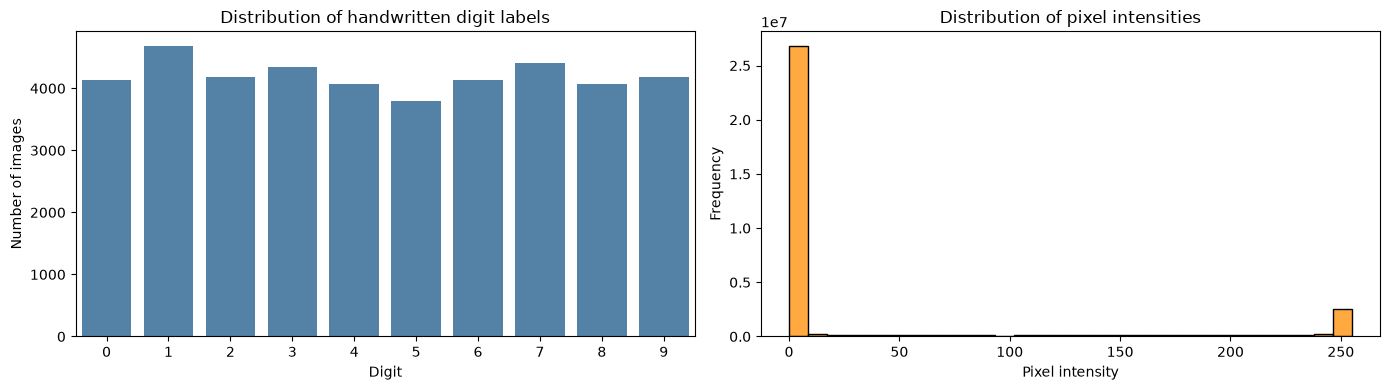

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.countplot(x=train_df["label"], ax=axes[0], color="steelblue")
axes[0].set_title("Distribution of handwritten digit labels")
axes[0].set_xlabel("Digit")
axes[0].set_ylabel("Number of images")

sns.histplot(
    train_df[pixel_columns].to_numpy().ravel(),
    bins=30, ax=axes[1], color="darkorange"
)
axes[1].set_title("Distribution of pixel intensities")
axes[1].set_xlabel("Pixel intensity")
axes[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

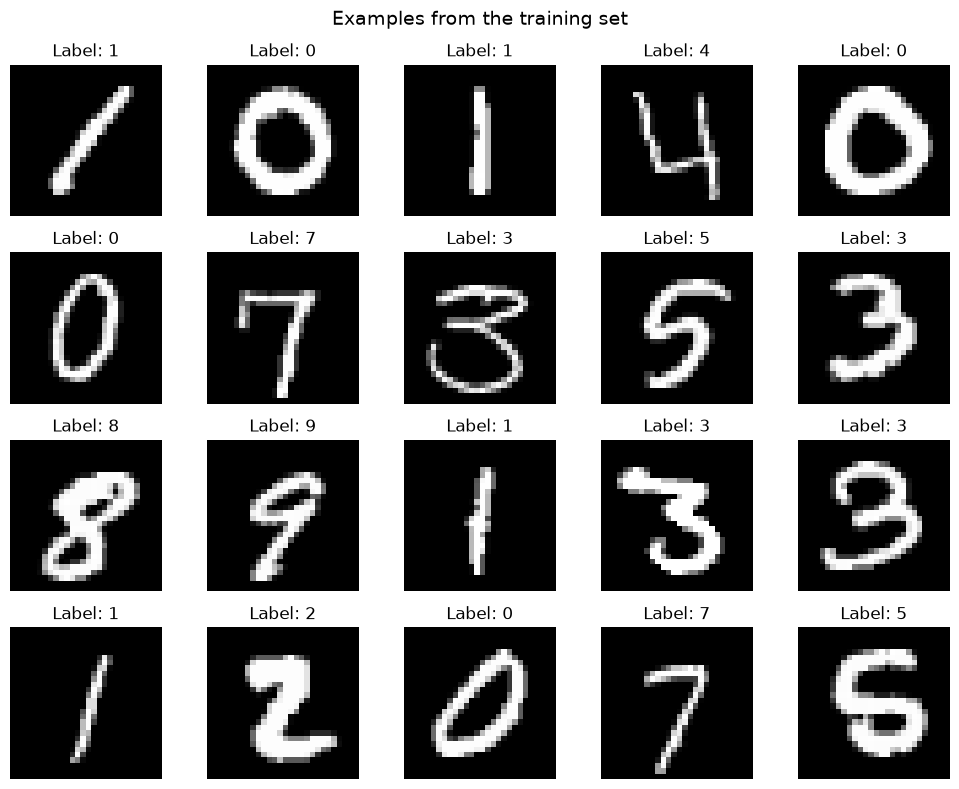

In [6]:
X_all = train_df.drop(columns="label").to_numpy(dtype=np.float32)
y_all = train_df["label"].to_numpy(dtype=np.int64)
X_test_raw = test_df.to_numpy(dtype=np.float32)

def show_digit_grid(images, labels=None, n=20, columns=5, title="Sample digits"):
    n = min(n, len(images))
    rows = int(np.ceil(n / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(columns * 2, rows * 2))
    axes = np.array(axes).reshape(-1)

    for i in range(len(axes)):
        axes[i].axis("off")
        if i < n:
            axes[i].imshow(images[i].reshape(28, 28), cmap="gray")
            if labels is not None:
                axes[i].set_title(f"Label: {labels[i]}")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.show()

show_digit_grid(X_all, y_all, n=20, title="Examples from the training set")

## Data Preparation

In [7]:
X_train_raw, X_valid_raw, y_train, y_valid = train_test_split(
    X_all, y_all,
    test_size=0.20,
    random_state=SEED,
    stratify=y_all
)

X_train = X_train_raw / 255.0
X_valid = X_valid_raw / 255.0
X_test = X_test_raw / 255.0

X_train_img = X_train.reshape(-1, 28, 28, 1)
X_valid_img = X_valid.reshape(-1, 28, 28, 1)
X_test_img = X_test.reshape(-1, 28, 28, 1)

print("Training split:", X_train.shape)
print("Validation split:", X_valid.shape)
print("Test set:", X_test.shape)
print("Image tensor:", X_train_img.shape)

Training split: (33600, 784)
Validation split: (8400, 784)
Test set: (28000, 784)
Image tensor: (33600, 28, 28, 1)


# Machine Learning Algorithms

## Logistic Regression Baseline

In [8]:
results = []
trained_models = {}

log_reg = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1200,
        solver="lbfgs",
        C=3.0,
        random_state=SEED
    ))
])

log_reg.fit(X_train, y_train)
pred_log = log_reg.predict(X_valid)
acc_log = accuracy_score(y_valid, pred_log)

trained_models["Logistic Regression"] = log_reg
results.append({"Model": "Logistic Regression", "Validation Accuracy": acc_log})

print(f"Logistic Regression accuracy: {acc_log:.5f}")

Logistic Regression accuracy: 0.89655


## Random Forest

In [9]:
random_forest = RandomForestClassifier(
    n_estimators=300,
    max_features="sqrt",
    min_samples_leaf=1,
    n_jobs=-1,
    random_state=SEED
)

random_forest.fit(X_train_raw, y_train)
pred_rf = random_forest.predict(X_valid_raw)
acc_rf = accuracy_score(y_valid, pred_rf)

trained_models["Random Forest"] = random_forest
results.append({"Model": "Random Forest", "Validation Accuracy": acc_rf})

print(f"Random Forest accuracy: {acc_rf:.5f}")

Random Forest accuracy: 0.96679


## Extremely Randomized Trees (Extra Trees)

In [10]:
extra_trees = ExtraTreesClassifier(
    n_estimators=400,
    max_features="sqrt",
    min_samples_leaf=1,
    n_jobs=-1,
    random_state=SEED
)

extra_trees.fit(X_train_raw, y_train)
pred_et = extra_trees.predict(X_valid_raw)
acc_et = accuracy_score(y_valid, pred_et)

trained_models["Extra Trees"] = extra_trees
results.append({"Model": "Extra Trees", "Validation Accuracy": acc_et})

print(f"Extra Trees accuracy: {acc_et:.5f}")

Extra Trees accuracy: 0.96988


## Support Vector Machine (RBF kernel)

In [11]:
RUN_SVM = True
SVM_MAX_TRAIN_ROWS = 18000  # Set to None to use the full training split.

if RUN_SVM:
    if SVM_MAX_TRAIN_ROWS is not None and SVM_MAX_TRAIN_ROWS < len(X_train):
        X_svm, _, y_svm, _ = train_test_split(
            X_train, y_train,
            train_size=SVM_MAX_TRAIN_ROWS,
            random_state=SEED,
            stratify=y_train
        )
    else:
        X_svm, y_svm = X_train, y_train

    svm_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(
            C=8.0,
            kernel="rbf",
            gamma="scale",
            cache_size=1500
        ))
    ])

    svm_model.fit(X_svm, y_svm)
    pred_svm = svm_model.predict(X_valid)
    acc_svm = accuracy_score(y_valid, pred_svm)

    trained_models["RBF SVM"] = svm_model
    results.append({"Model": "RBF SVM", "Validation Accuracy": acc_svm})
    print(f"RBF SVM accuracy: {acc_svm:.5f}")
else:
    print("SVM skipped.")

RBF SVM accuracy: 0.95536


# Neural Networks (NN)

## MLP

In [12]:
mlp_model = MLPClassifier(
    hidden_layer_sizes=(512, 256),
    activation="relu",
    solver="adam",
    alpha=1e-4,
    batch_size=256,
    learning_rate_init=1e-3,
    max_iter=35,
    early_stopping=True,
    validation_fraction=0.12,
    n_iter_no_change=5,
    random_state=SEED,
    verbose=True
)

mlp_model.fit(X_train, y_train)
pred_mlp = mlp_model.predict(X_valid)
acc_mlp = accuracy_score(y_valid, pred_mlp)

trained_models["MLP Neural Network"] = mlp_model
results.append({"Model": "MLP Neural Network", "Validation Accuracy": acc_mlp})

print(f"MLP accuracy: {acc_mlp:.5f}")

Iteration 1, loss = 0.39649620
Validation score: 0.950149
Iteration 2, loss = 0.14311833
Validation score: 0.963046
Iteration 3, loss = 0.08722634
Validation score: 0.962798
Iteration 4, loss = 0.06017278
Validation score: 0.963790
Iteration 5, loss = 0.04295653
Validation score: 0.969494
Iteration 6, loss = 0.03095879
Validation score: 0.970982
Iteration 7, loss = 0.02124660
Validation score: 0.972222
Iteration 8, loss = 0.01466275
Validation score: 0.973958
Iteration 9, loss = 0.00909427
Validation score: 0.973710
Iteration 10, loss = 0.00789491
Validation score: 0.969742
Iteration 11, loss = 0.00757891
Validation score: 0.973710
Iteration 12, loss = 0.00550500
Validation score: 0.973462
Iteration 13, loss = 0.00522423
Validation score: 0.974702
Iteration 14, loss = 0.00467865
Validation score: 0.972470
Iteration 15, loss = 0.00633268
Validation score: 0.974206
Iteration 16, loss = 0.00671094
Validation score: 0.973958
Iteration 17, loss = 0.01461905
Validation score: 0.970238
Iterat

## Convolutional Neural Network (CNN)

In [14]:
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers

    TF_AVAILABLE = True
    tf.keras.utils.set_random_seed(SEED)
    print("TensorFlow:", tf.__version__)
except Exception as error:
    TF_AVAILABLE = False
    print("TensorFlow is unavailable; CNN section will be skipped.")
    print("Reason:", error)

TensorFlow: 2.22.0-rc0


In [ ]:
cnn_model = None
cnn_history = None
acc_cnn = None
pred_cnn = None

if TF_AVAILABLE:
    cnn_model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(32, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(32, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.20),

        layers.Conv2D(64, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(64, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.35),
        layers.Dense(10, activation="softmax")
    ])

    cnn_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    cnn_model.summary()

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=4,
            restore_best_weights=True,
            mode="max"
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
            verbose=1
        )
    ]

    cnn_history = cnn_model.fit(
        X_train_img, y_train,
        validation_data=(X_valid_img, y_valid),
        epochs=20,
        batch_size=128,
        callbacks=callbacks,
        verbose=1
    )

    valid_probabilities = cnn_model.predict(X_valid_img, verbose=0)
    pred_cnn = np.argmax(valid_probabilities, axis=1)
    acc_cnn = accuracy_score(y_valid, pred_cnn)

    results.append({"Model": "CNN", "Validation Accuracy": acc_cnn})
    print(f"CNN accuracy: {acc_cnn:.5f}")
else:
    print("CNN skipped because TensorFlow is not installed.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 28, 28, 32)     │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 28, 28, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 468,906 (1.79 MB)

 Trainable params: 468,266 (1.79 MB)

 Non-trainable params: 640 (2.50 KB)

Epoch 1/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 66s 242ms/step - accuracy: 0.9355 - loss: 0.2167 - val_accuracy: 0.1115 - val_loss: 4.8865 - learning_rate: 0.0010
Epoch 2/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 71s 272ms/step - accuracy: 0.9797 - loss: 0.0694 - val_accuracy: 0.9445 - val_loss: 0.1787 - learning_rate: 0.0010
Epoch 3/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 57s 218ms/step - accuracy: 0.9835 - loss: 0.0527 - val_accuracy: 0.9844 - val_loss: 0.0499 - learning_rate: 0.0010
Epoch 4/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 57s 218ms/step - accuracy: 0.9871 - loss: 0.0421 - val_accuracy: 0.9879 - val_loss: 0.0384 - learning_rate: 0.0010
Epoch 5/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 71s 268ms/step - accuracy: 0.9890 - loss: 0.0370 - val_accuracy: 0.9890 - val_loss: 0.0332 - learning_rate: 0.0010
Epoch 6/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 69s 263ms/step - accuracy: 0.9892 - loss: 0.0355 - val_accuracy: 0.9910 - val_loss: 0.0318 - learning_rate: 0.0010
Epoch 7/20
263/263 ━━━━━━━━━━━━━━━━━━━━ 56s 213ms/step - accuracy: 0.9

In [15]:
if TF_AVAILABLE and cnn_history is not None:
    history_df = pd.DataFrame(cnn_history.history)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(history_df["accuracy"], label="Training")
    axes[0].plot(history_df["val_accuracy"], label="Validation")
    axes[0].set_title("CNN accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()

    axes[1].plot(history_df["loss"], label="Training")
    axes[1].plot(history_df["val_loss"], label="Validation")
    axes[1].set_title("CNN loss")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

NameError: name 'cnn_history' is not defined

# Compare validation performance

In [ ]:
cnn_model = None
cnn_history = None
acc_cnn = None
pred_cnn = None

if TF_AVAILABLE:
    cnn_model = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),

        layers.Conv2D(32, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(32, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.20),

        layers.Conv2D(64, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(64, kernel_size=3, padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D(pool_size=2),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.BatchNormalization(),
        layers.Dropout(0.35),
        layers.Dense(10, activation="softmax")
    ])

    cnn_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    cnn_model.summary()

    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_accuracy",
            patience=4,
            restore_best_weights=True,
            mode="max"
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=2,
            min_lr=1e-5,
            verbose=1
        )
    ]

    cnn_history = cnn_model.fit(
        X_train_img, y_train,
        validation_data=(X_valid_img, y_valid),
        epochs=20,
        batch_size=128,
        callbacks=callbacks,
        verbose=1
    )

    valid_probabilities = cnn_model.predict(X_valid_img, verbose=0)
    pred_cnn = np.argmax(valid_probabilities, axis=1)
    acc_cnn = accuracy_score(y_valid, pred_cnn)

    results.append({"Model": "CNN", "Validation Accuracy": acc_cnn})
    print(f"CNN accuracy: {acc_cnn:.5f}")
else:
    print("CNN skipped because TensorFlow is not installed.")

# Detailed Evaluation of the Best Validation Model

best_model_name = results_df.loc[0, "Model"]
print("Best model based on validation accuracy:", best_model_name)

if best_model_name == "CNN":
    best_valid_predictions = pred_cnn
elif best_model_name == "MLP Neural Network":
    best_valid_predictions = pred_mlp
elif best_model_name == "RBF SVM":
    best_valid_predictions = pred_svm
elif best_model_name == "Extra Trees":
    best_valid_predictions = pred_et
elif best_model_name == "Random Forest":
    best_valid_predictions = pred_rf
else:
    best_valid_predictions = pred_log

print(classification_report(y_valid, best_valid_predictions, digits=4))

cm = confusion_matrix(y_valid, best_valid_predictions)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title(f"Confusion matrix — {best_model_name}")
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.tight_layout()
plt.show()

# Inspect Misclassified Examples

In [ ]:
wrong_indices = np.where(best_valid_predictions != y_valid)[0]
print("Number of validation errors:", len(wrong_indices))

if len(wrong_indices) > 0:
    show_n = min(20, len(wrong_indices))
    selected = wrong_indices[:show_n]

    fig, axes = plt.subplots(4, 5, figsize=(12, 10))
    for ax, idx in zip(axes.ravel(), selected):
        ax.imshow(X_valid_raw[idx].reshape(28, 28), cmap="gray")
        ax.set_title(
            f"True: {y_valid[idx]} | Pred: {best_valid_predictions[idx]}"
        )
        ax.axis("off")
    for ax in axes.ravel()[show_n:]:
        ax.axis("off")
    plt.suptitle("Examples misclassified by the selected model")
    plt.tight_layout()
    plt.show()
else:
    print("No validation errors for this model.")

# Final Model and Kaggle Submission

In [ ]:
# Build final feature representations.
X_full_scaled = X_all / 255.0
X_test_scaled = X_test_raw / 255.0
X_full_img = X_full_scaled.reshape(-1, 28, 28, 1)
X_test_img = X_test_scaled.reshape(-1, 28, 28, 1)

if best_model_name == "CNN":
    if not TF_AVAILABLE:
        raise RuntimeError("CNN was selected but TensorFlow is unavailable.")

    final_model = keras.models.clone_model(cnn_model)
    final_model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    final_callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=3, restore_best_weights=True
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5
        )
    ]

    # A small validation fraction is retained only for early stopping.
    final_model.fit(
        X_full_img, y_all,
        validation_split=0.08,
        epochs=20,
        batch_size=128,
        callbacks=final_callbacks,
        verbose=1
    )
    test_probabilities = final_model.predict(X_test_img, verbose=0)
    test_predictions = np.argmax(test_probabilities, axis=1)

elif best_model_name == "MLP Neural Network":
    final_model = MLPClassifier(
        hidden_layer_sizes=(512, 256),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        batch_size=256,
        learning_rate_init=1e-3,
        max_iter=35,
        early_stopping=True,
        validation_fraction=0.12,
        n_iter_no_change=5,
        random_state=SEED,
        verbose=True
    )
    final_model.fit(X_full_scaled, y_all)
    test_predictions = final_model.predict(X_test_scaled)

elif best_model_name == "RBF SVM":
    final_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(C=8.0, kernel="rbf", gamma="scale", cache_size=1500))
    ])
    final_model.fit(X_full_scaled, y_all)
    test_predictions = final_model.predict(X_test_scaled)

elif best_model_name == "Extra Trees":
    final_model = ExtraTreesClassifier(
        n_estimators=400, max_features="sqrt",
        min_samples_leaf=1, n_jobs=-1, random_state=SEED
    )
    final_model.fit(X_all, y_all)
    test_predictions = final_model.predict(X_test_raw)

elif best_model_name == "Random Forest":
    final_model = RandomForestClassifier(
        n_estimators=300, max_features="sqrt",
        min_samples_leaf=1, n_jobs=-1, random_state=SEED
    )
    final_model.fit(X_all, y_all)
    test_predictions = final_model.predict(X_test_raw)

else:
    final_model = Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=1200, solver="lbfgs", C=3.0, random_state=SEED
        ))
    ])
    final_model.fit(X_full_scaled, y_all)
    test_predictions = final_model.predict(X_test_scaled)

print("Predictions generated:", len(test_predictions))

## Kaggle submission file

In [ ]:
submission = pd.DataFrame({
    "ImageId": np.arange(1, len(test_predictions) + 1),
    "Label": test_predictions.astype(int)
})

submission.to_csv("submission.csv", index=False)

print("Submission shape:", submission.shape)
display(submission.head())
print("Saved to:", Path("submission.csv").resolve())

## Submission Validation Checks

In [ ]:
EXPECTED_TEST_ROWS = len(test_df)

assert list(submission.columns) == ["ImageId", "Label"], "Incorrect column names/order."
assert len(submission) == EXPECTED_TEST_ROWS, "Submission row count does not match test.csv."
assert submission["ImageId"].is_unique, "ImageId values must be unique."
assert submission["ImageId"].iloc[0] == 1, "ImageId must start at 1."
assert submission["ImageId"].iloc[-1] == EXPECTED_TEST_ROWS, "Unexpected final ImageId."
assert submission["Label"].notna().all(), "Predictions contain missing values."
assert submission["Label"].between(0, 9).all(), "Labels must be digits 0–9."
assert np.issubdtype(submission["Label"].dtype, np.integer), "Labels must be integers."

print("All submission checks passed.")
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())
print("Predicted digit counts:")
display(submission["Label"].value_counts().sort_index().to_frame("count"))